# Лабораторная 4. Квантование и бинаризация изображений

**Задание**

1. Загрузка изображения и преобразование цветного к полутоновому.
2. Квантование по яркости (с ручным заданием количества уровней).
3. Бинаризация:
   * бинаризация методом Оцу глобальная;
   * бинаризация методом Оцу локальная (с предварительным разбиением на фрагменты — по каждому своя бинаризация);
   * бинаризация методом Оцу иерархическая (выполняется с иерархическим разбиением каждой уже полученной области, пока возможно разбивать). Квантование с использованием найденных порогов.

Порог Оцу — точка, максимизирующая межклассовую дисперсию гистограммы яркости (OpenCV: `cv2.threshold(..., cv2.THRESH_OTSU)`).

Исходное изображение лежит в `assets/image.jpg`; вместо него можно положить своё под тем же именем.

## Импорты и пути

In [1]:
import cv2
import numpy as np
from collections import Counter
from matplotlib import pyplot as plt
from pathlib import Path

BASE_DIR = next((p for p in (Path("assets"), Path("lab4/assets")) if p.is_dir()), Path("assets"))
OUT_DIR = BASE_DIR.resolve().parent / "outputs"
OUT_DIR.mkdir(exist_ok=True)


def save(name, img):
    """Сохранить изображение в outputs/."""
    path = OUT_DIR / name
    if not cv2.imwrite(str(path), img):
        raise OSError(path)
    return path

## 1. Загрузка изображения и преобразование к полутоновому

In [2]:
image_path = str(BASE_DIR / "image.jpg")

image = cv2.imread(image_path, cv2.IMREAD_COLOR_RGB)
if image is None:
    raise FileNotFoundError(image_path)

r, g, b = image[:, :, 0], image[:, :, 1], image[:, :, 2]
gray = np.clip(0.299 * r + 0.587 * g + 0.114 * b, 0, 255).astype(np.uint8)
save("gray.png", gray)

difference = np.abs(gray.astype(int) - cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)).max()
print(f"размер: {image.shape[1]}x{image.shape[0]}")
print(f"яркость: min={gray.min()}, max={gray.max()}, средняя={gray.mean():.1f}")
print(f"отличие от cv2.cvtColor: {difference} (округление)")

размер: 596x380
яркость: min=1, max=254, средняя=136.1
отличие от cv2.cvtColor: 1 (округление)


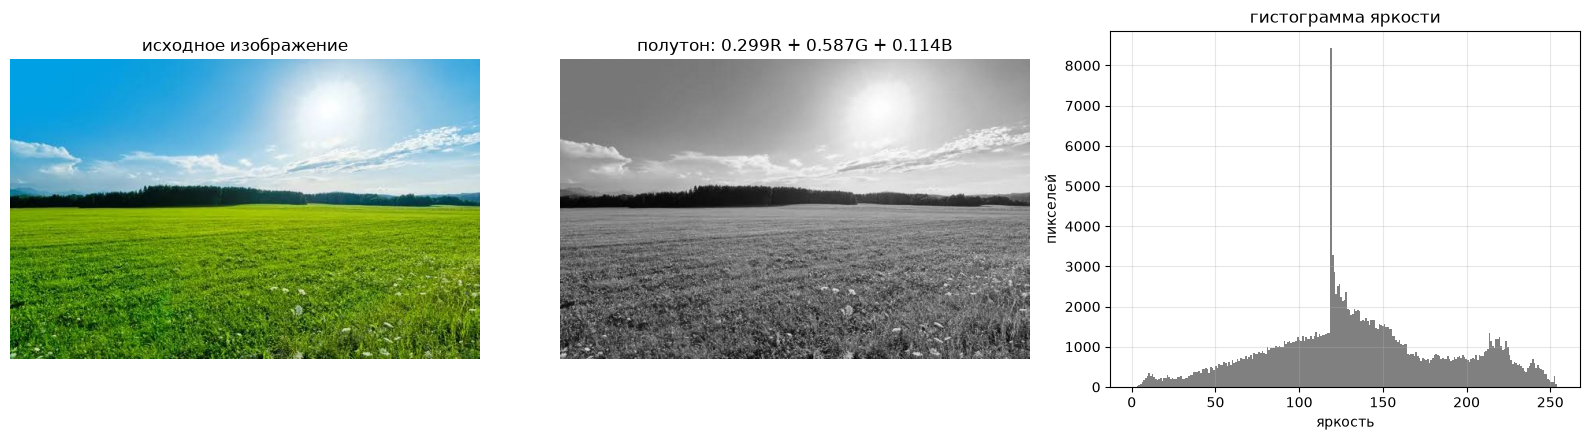

In [3]:
plt.figure(figsize=(16, 4.5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("исходное изображение")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray, "gray", vmin=0, vmax=255)
plt.title("полутон: 0.299R + 0.587G + 0.114B")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.hist(gray.ravel(), bins=256, range=(0, 255), color="0.5")
plt.title("гистограмма яркости")
plt.xlabel("яркость")
plt.ylabel("пикселей")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 2. Квантование по яркости

Количество уровней `L` задаётся вручную. Диапазон 0…255 делится на `L` равных интервалов:

* номер уровня: `k = floor(v * L / 256)`;
* значение после квантования: `k * 255 / (L - 1)` (крайние уровни остаются 0 и 255).

In [4]:
QUANT_LEVELS = 4


def quantize(gray, levels):
    """Квантование по яркости на заданное число уровней."""
    if levels < 2:
        raise ValueError("уровней должно быть не меньше двух")
    step = 256 / levels
    index = np.minimum((gray / step).astype(np.int32), levels - 1)
    return (index * 255 // (levels - 1)).astype(np.uint8), index


quantized, quant_index = quantize(gray, QUANT_LEVELS)
save(f"quantized_L{QUANT_LEVELS}.png", quantized)

counts = np.bincount(quant_index.ravel(), minlength=QUANT_LEVELS)
print("уровней:", QUANT_LEVELS)
print("различных значений яркости:", len(np.unique(quantized)))
print("пикселей по уровням:", counts)

уровней: 4
различных значений яркости: 4
пикселей по уровням: [20860 85684 77401 42535]


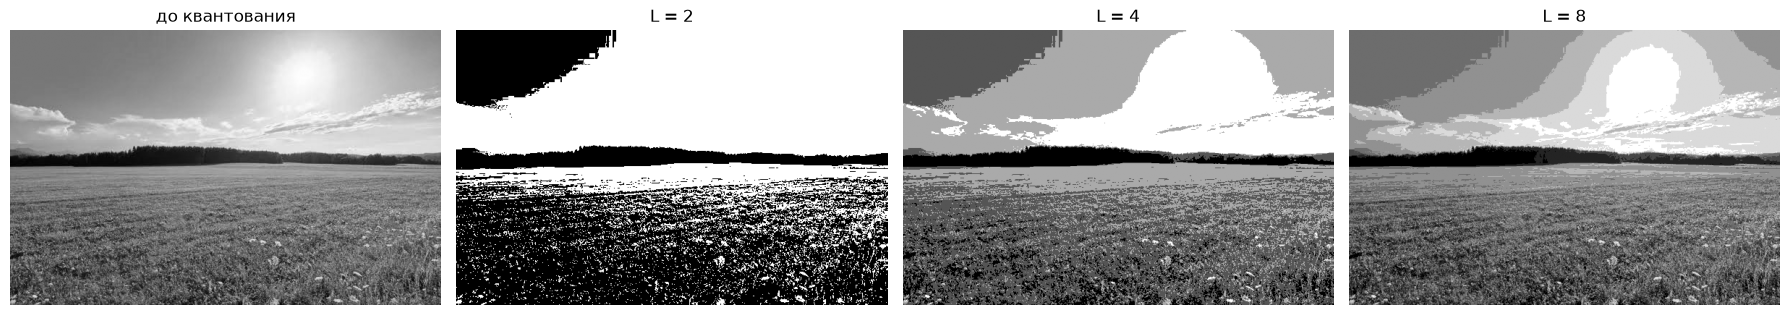

In [5]:
plt.figure(figsize=(18, 4.5))

plt.subplot(1, 4, 1)
plt.imshow(gray, "gray", vmin=0, vmax=255)
plt.title("до квантования")
plt.axis("off")

for position, levels in enumerate((2, 4, 8), start=2):
    plt.subplot(1, 4, position)
    plt.imshow(quantize(gray, levels)[0], "gray", vmin=0, vmax=255)
    plt.title(f"L = {levels}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Чем меньше уровней, тем грубее передаются плавные переходы: на градиенте неба
появляются ложные контуры. При `L = 8` изображение почти не отличается от полутонового.

## 3. Бинаризация

Пиксель ярче порога становится белым (255), остальные — чёрными (0).

### 3.1. Глобальная бинаризация Оцу

In [6]:
threshold_global, B_global = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
save("otsu_global.png", B_global)

print(f"порог Оцу: {threshold_global:.0f}")
print(f"светлых пикселей: {(B_global == 255).mean() * 100:.1f} %")

порог Оцу: 147
светлых пикселей: 37.4 %


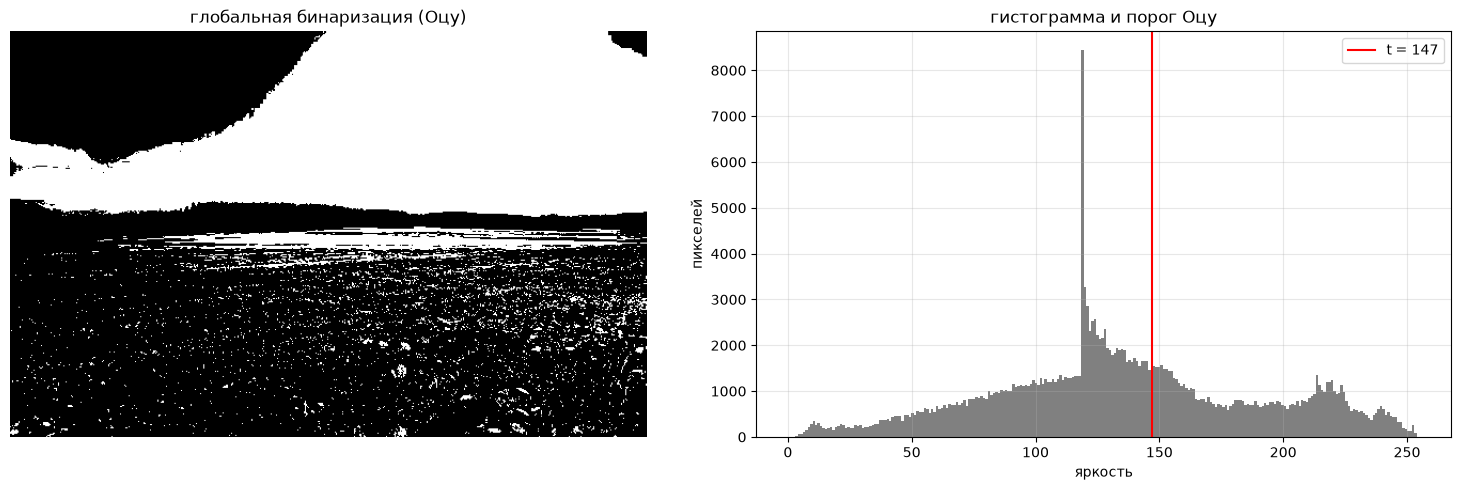

In [7]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.imshow(B_global, "gray", vmin=0, vmax=255)
plt.title("глобальная бинаризация (Оцу)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.hist(gray.ravel(), bins=256, range=(0, 255), color="0.5")
plt.axvline(threshold_global, color="red", label=f"t = {threshold_global:.0f}")
plt.title("гистограмма и порог Оцу")
plt.xlabel("яркость")
plt.ylabel("пикселей")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 3.2. Локальная бинаризация Оцу

Изображение заранее разбивается на фрагменты (сетка `cols × rows`), в каждом фрагменте
порог Оцу находится отдельно, и бинаризация выполняется только внутри своего фрагмента.
Так учитывается неравномерная освещённость: у светлой и у тёмной части свои пороги.
Плата за это — скачки порога на границах фрагментов.

In [8]:
LOCAL_GRID = (4, 3)  # (столбцов, строк)


def fragment_bounds(shape, cols, rows):
    """Границы фрагментов сетки cols x rows."""
    h, w = shape
    ys = np.linspace(0, h, rows + 1).round().astype(int)
    xs = np.linspace(0, w, cols + 1).round().astype(int)
    return [(y0, y1, x0, x1)
            for y0, y1 in zip(ys[:-1], ys[1:])
            for x0, x1 in zip(xs[:-1], xs[1:])]


def local_otsu(gray, cols, rows):
    """Своя бинаризация Оцу в каждом фрагменте."""
    out = np.zeros_like(gray)
    thresholds = np.zeros((rows, cols), np.int32)
    for index, (y0, y1, x0, x1) in enumerate(fragment_bounds(gray.shape, cols, rows)):
        patch = np.ascontiguousarray(gray[y0:y1, x0:x1])
        threshold, _ = cv2.threshold(patch, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        thresholds[index // cols, index % cols] = int(threshold)
        out[y0:y1, x0:x1] = np.where(patch > threshold, 255, 0)
    return out, thresholds


B_local, local_thresholds = local_otsu(gray, *LOCAL_GRID)
save("otsu_local.png", B_local)

print("фрагментов:", LOCAL_GRID[0] * LOCAL_GRID[1])
print(f"пороги: от {local_thresholds.min()} до {local_thresholds.max()}")

фрагментов: 12
пороги: от 85 до 211


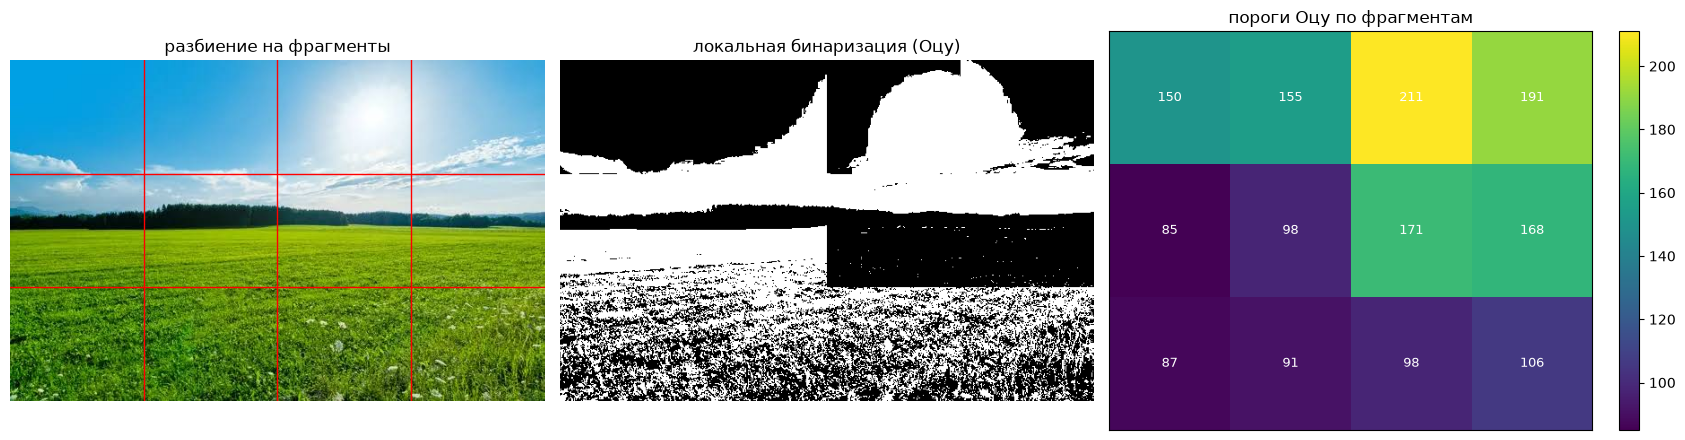

In [9]:
cols, rows = LOCAL_GRID

plt.figure(figsize=(17, 4.5))

plt.subplot(1, 3, 1)
plt.imshow(image)
ys = np.linspace(0, image.shape[0], rows + 1) - 0.5
xs = np.linspace(0, image.shape[1], cols + 1) - 0.5
for y in ys[1:-1]:
    plt.axhline(y, color="red", lw=1)
for x in xs[1:-1]:
    plt.axvline(x, color="red", lw=1)
plt.title("разбиение на фрагменты")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(B_local, "gray", vmin=0, vmax=255)
plt.title("локальная бинаризация (Оцу)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(local_thresholds, cmap="viridis", aspect="auto")
for (row, col), threshold in np.ndenumerate(local_thresholds):
    plt.text(col, row, threshold, ha="center", va="center", color="w", fontsize=9)
plt.title("пороги Оцу по фрагментам")
plt.colorbar(fraction=0.046)
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

Размер фрагмента задаёт компромисс: крупные фрагменты не отслеживают освещённость,
мелкие — сильнее реагируют на шум и однородные участки. У однородного фрагмента
гистограмма вырождена, и Оцу может вернуть 0 (весь фрагмент станет белым) — это
видно на сетке 8 × 6.

сетка 2x2: пороги от 87 до 135
сетка 4x3: пороги от 85 до 211
сетка 8x6: пороги от 83 до 237


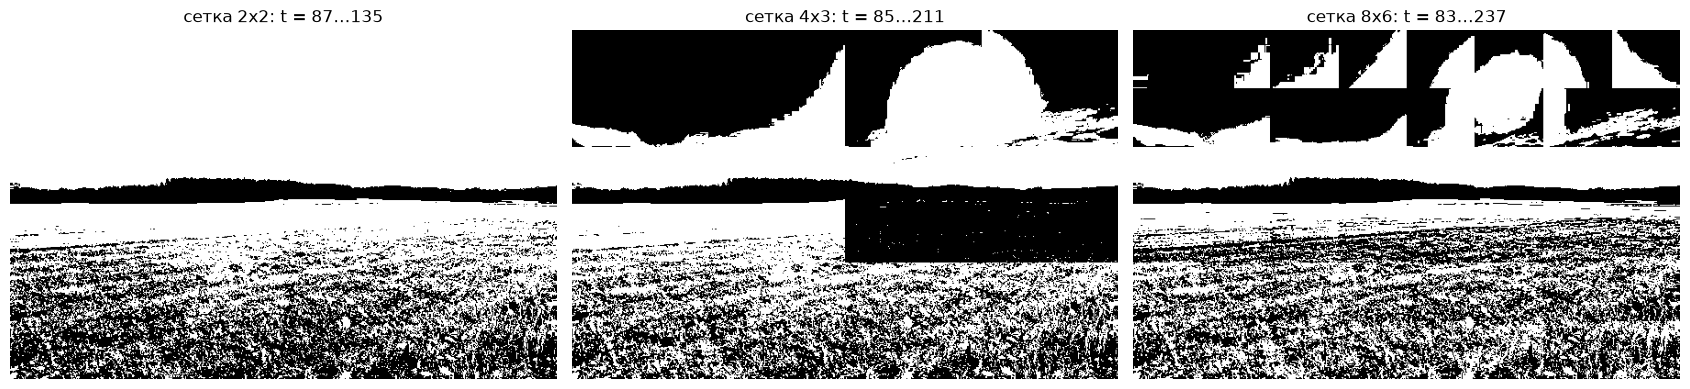

In [10]:
plt.figure(figsize=(17, 4.5))

for position, grid in enumerate(((2, 2), (4, 3), (8, 6)), start=1):
    result, thresholds = local_otsu(gray, *grid)
    plt.subplot(1, 3, position)
    plt.imshow(result, "gray", vmin=0, vmax=255)
    plt.title(f"сетка {grid[0]}x{grid[1]}: t = {thresholds.min()}…{thresholds.max()}")
    plt.axis("off")
    print(f"сетка {grid[0]}x{grid[1]}: пороги от {thresholds.min()} до {thresholds.max()}")

plt.tight_layout()
plt.show()

### 3.3. Иерархическая бинаризация Оцу

Вся картинка — корень дерева. Область делится на четыре части, пока это имеет смысл:

* сторона области не меньше `2 * MIN_FRAGMENT`;
* глубина меньше `MAX_DEPTH`;
* область неоднородна по яркости (`std > STD_MIN`).

Каждой области дерева считается свой порог Оцу, листья бинаризуются своим порогом.
Мелкие однородные области дальше не дробятся — дерево получается неравномерным.

In [11]:
MIN_FRAGMENT = 32   # половина минимальной стороны области
STD_MIN = 16        # разброс яркости, ниже которого область считается однородной
MAX_DEPTH = 4


class Region:
    """Узел дерева разбиения: область, её порог Оцу и потомки."""

    def __init__(self, y0, y1, x0, x1, depth):
        self.y0, self.y1, self.x0, self.x1 = y0, y1, x0, x1
        self.depth = depth
        patch = np.ascontiguousarray(gray[y0:y1, x0:x1])
        threshold, _ = cv2.threshold(patch, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        self.threshold = int(threshold)
        self.std = float(patch.std())
        self.children = []
        self.is_leaf = True


def splittable(region):
    """Область большая и неоднородная — её можно делить дальше."""
    height = region.y1 - region.y0
    width = region.x1 - region.x0
    return (region.depth < MAX_DEPTH
            and height >= 2 * MIN_FRAGMENT
            and width >= 2 * MIN_FRAGMENT
            and region.std > STD_MIN)


def grow(region):
    """Рекурсивное деление области на четыре части."""
    if not splittable(region):
        return
    region.is_leaf = False
    y_mid = (region.y0 + region.y1) // 2
    x_mid = (region.x0 + region.x1) // 2
    for y0, y1 in ((region.y0, y_mid), (y_mid, region.y1)):
        for x0, x1 in ((region.x0, x_mid), (x_mid, region.x1)):
            child = Region(y0, y1, x0, x1, region.depth + 1)
            region.children.append(child)
            grow(child)


def leaves(region):
    """Листовые области дерева."""
    if region.is_leaf:
        yield region
        return
    for child in region.children:
        yield from leaves(child)


root = Region(0, gray.shape[0], 0, gray.shape[1], 0)
grow(root)
leaf_regions = list(leaves(root))

print("листьев:", len(leaf_regions))
for depth, count in sorted(Counter(region.depth for region in leaf_regions).items()):
    print(f"  глубина {depth}: {count} областей")

листьев: 58
  глубина 2: 2 областей
  глубина 3: 56 областей


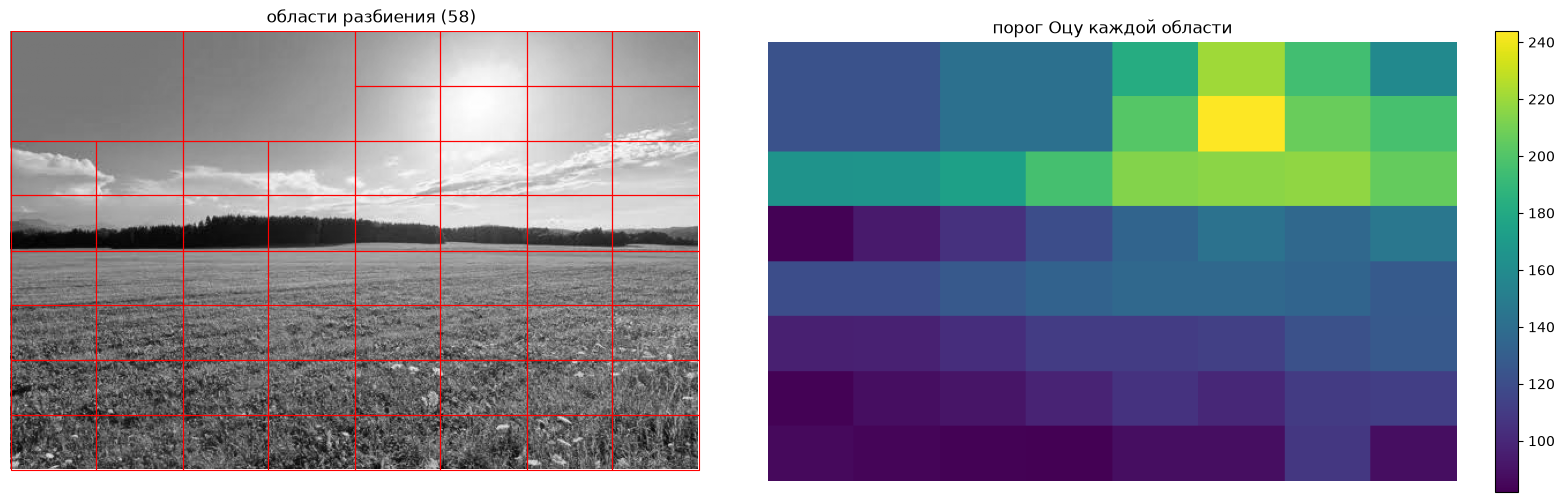

In [12]:
threshold_map = np.zeros_like(gray, dtype=np.float32)
for region in leaf_regions:
    threshold_map[region.y0:region.y1, region.x0:region.x1] = region.threshold

plt.figure(figsize=(16, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, "gray", vmin=0, vmax=255)
for region in leaf_regions:
    plt.plot([region.x0, region.x1, region.x1, region.x0, region.x0],
             [region.y0, region.y0, region.y1, region.y1, region.y0],
             color="red", lw=0.8)
plt.title(f"области разбиения ({len(leaf_regions)})")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(threshold_map, cmap="viridis")
plt.title("порог Оцу каждой области")
plt.colorbar(fraction=0.046)
plt.axis("off")

plt.tight_layout()
plt.show()

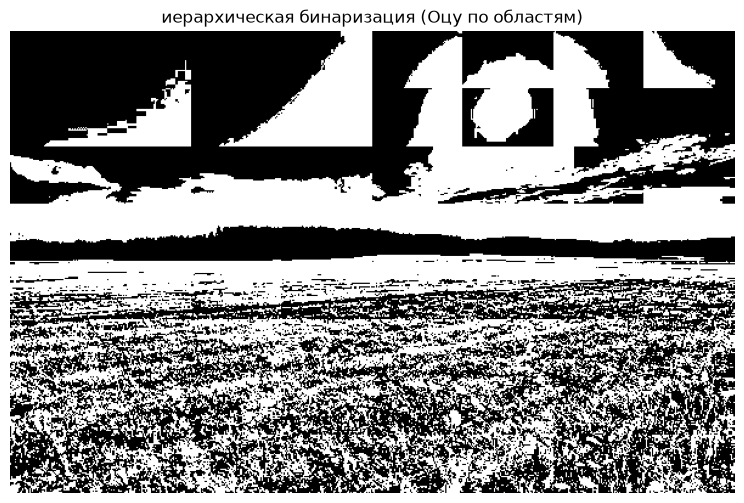

In [13]:
B_hier = np.zeros_like(gray)
for region in leaf_regions:
    patch = gray[region.y0:region.y1, region.x0:region.x1]
    B_hier[region.y0:region.y1, region.x0:region.x1] = np.where(patch > region.threshold, 255, 0)

save("otsu_hierarchical.png", B_hier)

plt.figure(figsize=(12, 6))
plt.imshow(B_hier, "gray", vmin=0, vmax=255)
plt.title("иерархическая бинаризация (Оцу по областям)")
plt.axis("off")
plt.show()

#### Квантование с использованием найденных порогов

Пороги всех листьев сортируются и образуют границы уровней. Уровень пикселя —
число порогов, которые он превышает: `k = |{t : t < v}|`. Получается `N + 1` уровень
для `N` различных порогов; значения уровней раскладываются на диапазон 0…255.
Пороги найдены для отдельных областей, но как границы уровней применяются ко всему
изображению — получается квантование по локально найденным порогам.

In [14]:
hier_thresholds = np.array(sorted({region.threshold for region in leaf_regions}))
number_of_levels = len(hier_thresholds) + 1

level_index = np.searchsorted(hier_thresholds, gray, side="left")
quantized_hier = (level_index * 255 // (number_of_levels - 1)).astype(np.uint8)
save("otsu_hierarchical_quantized.png", quantized_hier)

print("найдено порогов:", len(hier_thresholds), "-> уровней квантования:", number_of_levels)
print("пороги:", hier_thresholds)

найдено порогов: 46 -> уровней квантования: 47
пороги: [ 82  83  84  86  88  91  94  96  97  98 100 103 105 106 108 110 111 112
 113 120 122 123 127 128 133 134 137 142 143 146 159 165 166 174 182 195
 196 197 201 206 207 214 216 217 221 244]


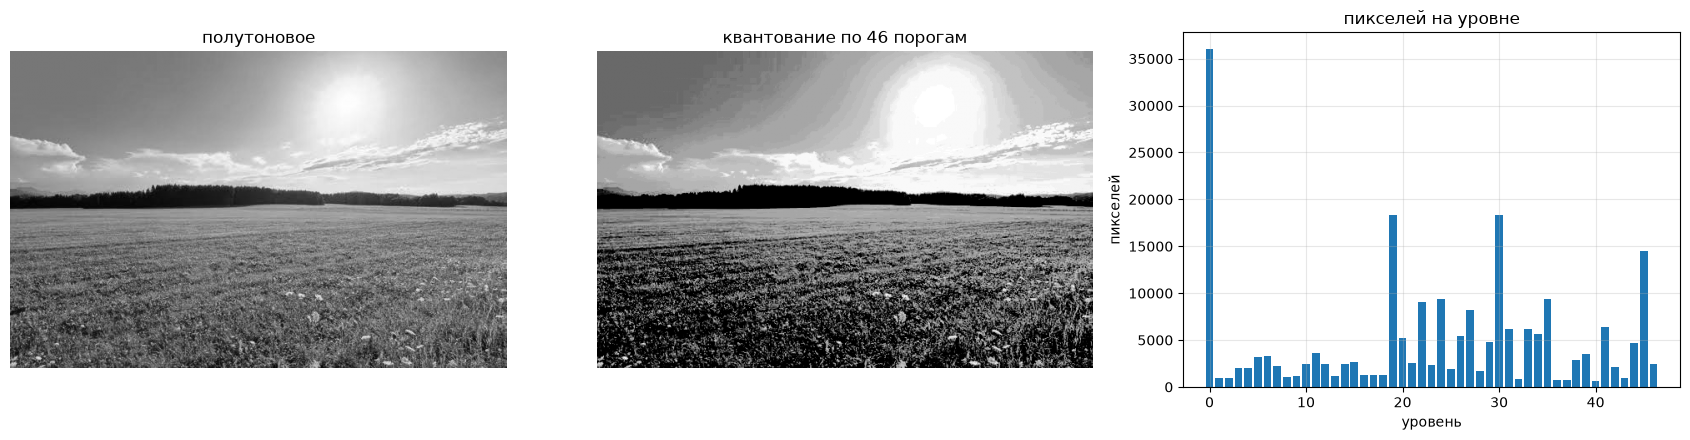

In [15]:
plt.figure(figsize=(17, 4.5))

plt.subplot(1, 3, 1)
plt.imshow(gray, "gray", vmin=0, vmax=255)
plt.title("полутоновое")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(quantized_hier, "gray", vmin=0, vmax=255)
plt.title(f"квантование по {len(hier_thresholds)} порогам")
plt.axis("off")

plt.subplot(1, 3, 3)
counts = np.bincount(level_index.ravel(), minlength=number_of_levels)
plt.bar(np.arange(number_of_levels), counts)
plt.title("пикселей на уровне")
plt.xlabel("уровень")
plt.ylabel("пикселей")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Сравнение результатов

In [16]:
def agreement(first, second):
    """Доля пикселей с одинаковым решением (порог 127)."""
    return np.mean((first > 127) == (second > 127)) * 100


print(f"глобальная и локальная совпадают: {agreement(B_global, B_local):.1f} %")
print(f"глобальная и иерархическая совпадают: {agreement(B_global, B_hier):.1f} %")

глобальная и локальная совпадают: 65.9 %
глобальная и иерархическая совпадают: 63.8 %


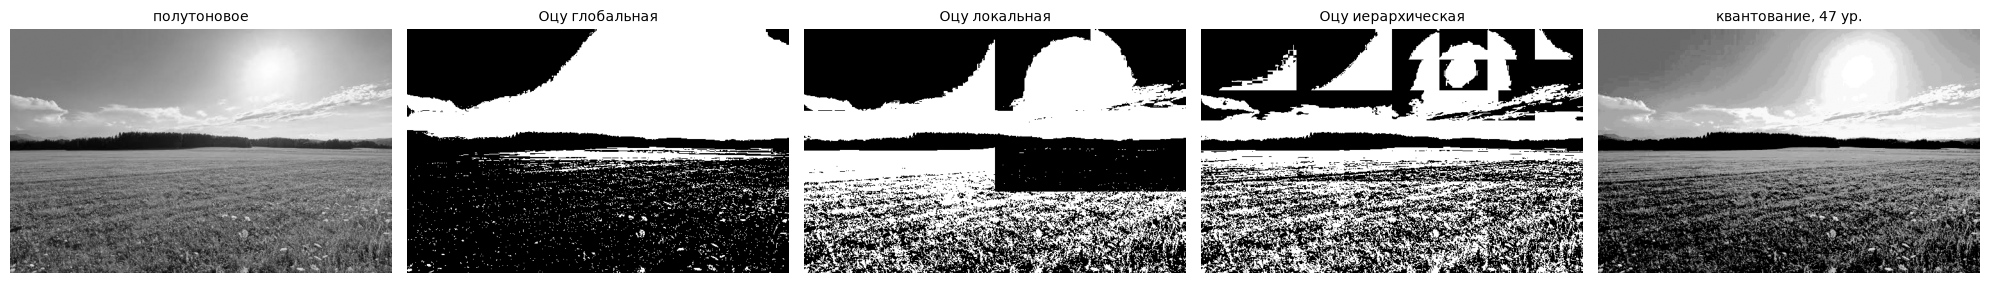

In [17]:
results = [("полутоновое", gray),
           ("Оцу глобальная", B_global),
           ("Оцу локальная", B_local),
           ("Оцу иерархическая", B_hier),
           (f"квантование, {number_of_levels} ур.", quantized_hier)]

plt.figure(figsize=(20, 4.8))
for position, (title, img) in enumerate(results, start=1):
    plt.subplot(1, len(results), position)
    plt.imshow(img, "gray", vmin=0, vmax=255)
    plt.title(title, fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.savefig(OUT_DIR / "comparison.png", dpi=120)
plt.show()

## Выводы

* Глобальный порог Оцу один для всего кадра: он хорошо работает, когда изображение
  двухмодально, но при неравномерной освещённости тёмная и светлая части «тянут»
  порог каждая в свою сторону — часть объектов теряется, часть фона становится белой.
* Локальный Оцу подстраивается под освещённость фрагмента, детали на свету и в тени
  видны одновременно, но пороги соседних фрагментов скачут — на границах заметны
  швы, а однородные фрагменты дают вырожденные значения.
* Иерархический Оцу даёт неравномерную сетку: однородные области остаются крупными,
  неоднородные дробятся, и каждая получает свой порог. Найденные пороги можно
  использовать как границы уровней — получается многоуровневое квантование,
  где число уровней определяется структурой изображения, а не задаётся вручную.
* Мелкий «спекл» на траве — это текстура поверхности, а не ошибка метода: порог
  принимает решения по каждому пикселю. Небольшое размытие перед бинаризацией
  уменьшает такой шум, но сглаживает мелкие детали.
* Итоговое число уровней зависит от параметров разбиения (`MIN_FRAGMENT`, `STD_MIN`,
  `MAX_DEPTH`): ужесточение условий делает дерево грубее, а квантование — контрастнее.